# Data Acquisition and Preparation

This section loads the original Card and Krueger (1994) fast-food restaurant dataset, retrieves the accompanying codebook, and prepares the data for analysis. The codebook is used to assign descriptive column names, while employment variables are converted to numeric format for subsequent calculations.

In [159]:
import pandas as pd
import requests
import zipfile
from io import BytesIO, TextIOWrapper
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Download and extract the original Card-Krueger dataset
r = requests.get("https://davidcard.berkeley.edu/data_sets/njmin.zip")
z = zipfile.ZipFile(BytesIO(r.content))

# Load the raw restaurant-level data; column names are assigned from the codebook below
df = pd.read_csv(z.open("public.dat"), engine="python", sep=r"\s+", header=None)

# Inspect the dataset dimensions and first few observations
print(df.shape)
df.head()


(410, 46)


,0,1,2,3,4,5,6,7,8,9,...,36,37,38,39,40,41,42,43,44,45
0,46,1,0,0,0,0,0,1,0,0,...,0.08,1,2,6.50,16.50,1.03,.,0.94,4,4
1,49,2,0,0,0,0,0,1,0,0,...,0.05,0,2,10.00,13.00,1.01,0.89,2.35,4,4
2,506,2,1,0,0,0,0,1,0,0,...,0.25,.,1,11.00,11.00,0.95,0.74,2.33,4,3
3,56,4,1,0,0,0,0,1,0,0,...,0.15,0,2,10.00,12.00,0.92,0.79,0.87,2,2
4,61,4,1,0,0,0,0,1,0,0,...,0.15,0,2,10.00,12.00,1.01,0.84,0.95,2,2


### Loading the Codebook and Labeling Variables

The original dataset is stored in `public.dat`, which contains observations without descriptive column names. The accompanying codebook documents the variables and their meanings. I extract the relevant variable names and descriptions from the codebook and use them to label the columns of the DataFrame.

In [160]:
# Read the codebook as text and extract the relevant variable definitions
codebook = [repr(line) for line in TextIOWrapper(z.open("codebook"), "cp437")]

# Select the codebook lines containing variable names and descriptions
codes = codebook[7:11] + codebook[13:19] + \
        codebook[21:38] + codebook[40:59]

# Extract variable names and their descriptions
cols = [i.strip("'\" ").split()[0] for i in codes]
descriptions = [" ".join(i.strip("'\" ").split()[4:]).rstrip('\\n')
                for i in codes]
column_descriptions = dict(zip(cols, descriptions))

# Assign the extracted variable names to the dataset
df.columns = cols
df.columns = df.columns.str.lower()

# Verify the column names and inspect the employment variables
print(df.columns.tolist())
df[['empft', 'emppt', 'nmgrs']]

['sheet', 'chain', 'co_owned', 'state', 'southj', 'centralj', 'northj', 'pa1', 'pa2', 'shore', 'ncalls', 'empft', 'emppt', 'nmgrs', 'wage_st', 'inctime', 'firstinc', 'bonus', 'pctaff', 'meals', 'open', 'hrsopen', 'psoda', 'pfry', 'pentree', 'nregs', 'nregs11', 'type2', 'status2', 'date2', 'ncalls2', 'empft2', 'emppt2', 'nmgrs2', 'wage_st2', 'inctime2', 'firstin2', 'special2', 'meals2', 'open2r', 'hrsopen2', 'psoda2', 'pfry2', 'pentree2', 'nregs2', 'nregs112']


,empft,emppt,nmgrs
0,30.00,15.00,3.00
1,6.50,6.50,4.00
2,3.00,7.00,2.00
3,20.00,20.00,4.00
4,6.00,26.00,5.00
...,...,...,...
405,2.00,10.00,2.00
406,3.50,6.50,3.00
407,3.00,33.00,5.00
408,7.00,8.00,3.00


In [161]:
# Convert employment variables to numeric, treating "." as missing data
fte_cols = ['empft', 'emppt', 'nmgrs', 'empft2', 'emppt2', 'nmgrs2']

for col in fte_cols:
    df[col] = pd.to_numeric(
        df[col].replace('.', float('nan')),
        errors='coerce')

## Constructing Employment Measures

The paper measures restaurant employment using full-time-equivalent (FTE) employment. Full-time workers count as one employee, part-time workers receive a weight of 0.5, and managers are included in the baseline measure. The employment variables without a suffix refer to the initial survey, while those ending in `2` refer to the follow-up survey.

To examine whether the results depend on how employment is defined, I construct alternative measures that exclude managers or assign part-time workers weights of 0.4 and 0.6. These alternative measures are used for robustness checks, allowing me to assess whether the estimated employment effect is sensitive to the assumptions used to calculate FTE employment.

In [162]:
# Baseline FTE employment measure: part-time employees receive a weight of 0.5, and managers are included.
df['fte'] = df['empft'] + df['emppt'] * 0.5 + df['nmgrs']
df['fte_after'] = df['empft2'] + df['emppt2'] * 0.5 + df['nmgrs2']

# Robustness checks: exclude managers and vary the part-time employee weight.
df['fte2'] = df['empft'] + df['emppt'] * 0.5
df['fte_after2'] = df['empft2'] + df['emppt2'] * 0.5

df['fte3'] = df['empft'] + df['emppt'] * 0.4 + df['nmgrs']
df['fte_after3'] = df['empft2'] + df['emppt2'] * 0.4 + df['nmgrs2']

df['fte4'] = df['empft'] + df['emppt'] * 0.6 + df['nmgrs']
df['fte_after4'] = df['empft2'] + df['emppt2'] * 0.6 + df['nmgrs2']

## Recreating Table 2: Distribution of Starting Wages

This section examines the distribution of restaurant starting wages in February 1992, before New Jersey implemented its minimum-wage increase. I group restaurants into starting-wage categories and count the number of restaurants in each category separately for Pennsylvania and New Jersey. I then convert these counts into percentages of the respective state samples to make the distributions comparable despite differences in sample size.

The resulting table and bar chart provide descriptive evidence about the starting-wage distributions in the two states before the policy change. This helps characterize the treatment and control groups, although the distribution alone does not establish the causal effect of the minimum-wage increase.

In [163]:
# Prepare state and starting-wage variables for Table 2.
df['state'] = df['state'].astype(str)
df['wage_st'] = pd.to_numeric(df['wage_st'], errors='coerce')
table2 = df[['wage_st', 'state']].copy()

# Group starting wages into $0.10 intervals.
bins = np.arange(4.19, 5.81, 0.1)
labels = [str(round(x, 2)) for x in np.arange(4.25, 5.81, 0.1)]
table2['category'] = pd.cut(table2['wage_st'], bins=bins, labels=labels)

# Count restaurants in each state and wage category, then reshape into separate state columns.
table2_counts = table2.value_counts(['state', 'category']).reset_index()
table2_countsp = table2_counts.pivot_table(
    index='category', columns='state', values='count', fill_value=0
).reset_index()

# Check the number of restaurants included for each state.
print(table2_countsp['0'].sum())
print(table2_countsp['1'].sum())

# Calculate each wage category's percentage of the state's restaurant sample.
table2_countsp['pa_percent'] = (table2_countsp['0'] / 76) * 100
table2_countsp['nj_percent'] = (table2_countsp['1'] / 314) * 100

table2_countsp.columns.name = None
table2_countsp

76.0
314.0


/tmp/ipykernel_720/1509164991.py:13: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  table2_countsp = table2_counts.pivot_table(


,category,0,1,pa_percent,nj_percent
0,4.25,26.0,101.0,34.210526,32.165605
1,4.35,1.0,12.0,1.315789,3.821656
2,4.45,0.0,3.0,0.000000,0.955414
3,4.55,13.0,52.0,17.105263,16.560510
4,4.65,1.0,20.0,1.315789,6.369427
5,4.75,10.0,38.0,13.157895,12.101911
6,4.85,1.0,13.0,1.315789,4.140127
7,4.95,0.0,2.0,0.000000,0.636943
8,5.05,20.0,50.0,26.315789,15.923567
9,5.15,0.0,5.0,0.000000,1.592357


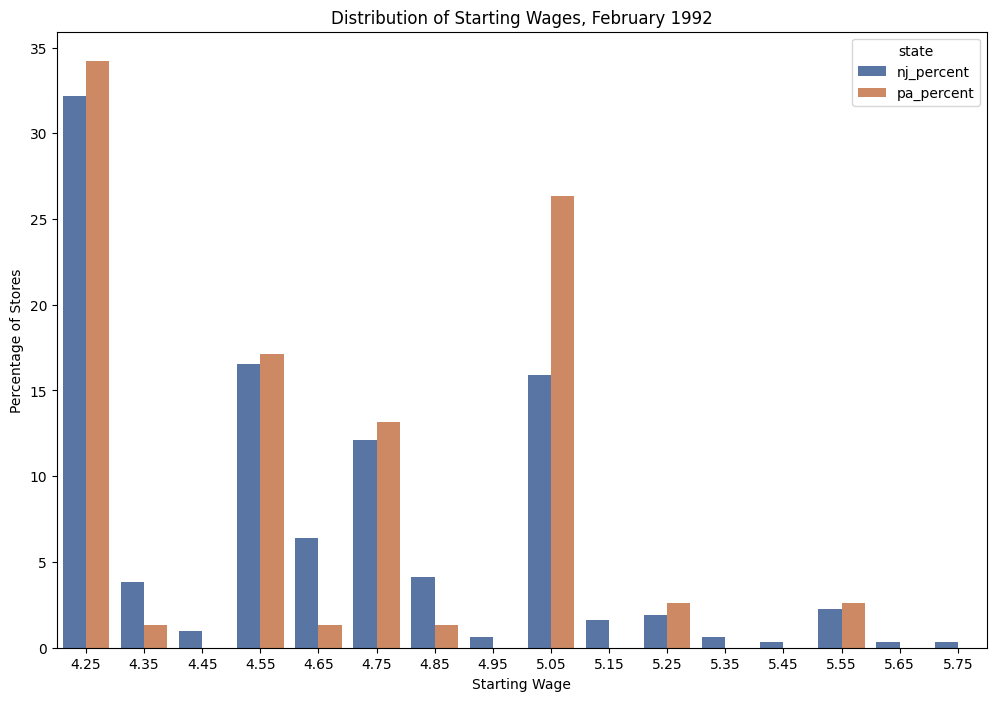

In [164]:
# Reshape the state percentage columns into a long format suitable for seaborn.
# Each row contains a wage category, a state label, and the corresponding percentage.
table2_graph = pd.melt(
    table2_countsp,
    id_vars=["category"],
    value_vars=["nj_percent", "pa_percent"],
    var_name="state",
    value_name="percentage"
)

# Plot the percentage distribution of starting wages before the minimum-wage increase.
plt.figure(figsize=(12, 8))
sns.barplot(
    data=table2_graph,
    x='category',
    y='percentage',
    hue='state',
    palette='deep'
)
plt.title('Distribution of Starting Wages, February 1992')
plt.xlabel('Starting Wage')
plt.ylabel('Percentage of Stores');

In [165]:
# Recreate Table 3 using starting wages from November 1992, after the minimum-wage increase.
df['wage_st2'] = pd.to_numeric(df['wage_st2'], errors='coerce')
table3 = df[['wage_st2', 'state']].copy()

# Group starting wages into $0.10 intervals.
bins = np.arange(4.19, 6.41, 0.1)
labels = [str(round(x, 2)) for x in np.arange(4.25, 6.36, 0.1)]
table3['category'] = pd.cut(table3['wage_st2'], bins=bins, labels=labels)

# Count restaurants in each state and wage category, then reshape into separate state columns.
table3_counts = table3.value_counts(['state', 'category']).reset_index()
table3_countsp = table3_counts.pivot_table(
    index='category', columns='state', values='count', fill_value=0
).reset_index()

# Check the number of restaurants included for each state.
print(table3_countsp['0'].sum())
print(table3_countsp['1'].sum())

# Calculate each wage category's percentage of the state's restaurant sample.
table3_countsp['pa_percent'] = (table3_countsp['0'] / 71) * 100
table3_countsp['nj_percent'] = (table3_countsp['1'] / 318) * 100
table3_countsp.columns.name = None

table3_countsp

71.0
318.0


/tmp/ipykernel_720/173706900.py:12: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  table3_countsp = table3_counts.pivot_table(


,category,0,1,pa_percent,nj_percent
0,4.25,20.0,0.0,28.169014,0.000000
1,4.35,5.0,0.0,7.042254,0.000000
2,4.45,2.0,0.0,2.816901,0.000000
3,4.55,11.0,0.0,15.492958,0.000000
4,4.75,14.0,0.0,19.718310,0.000000
5,4.95,3.0,0.0,4.225352,0.000000
6,5.05,14.0,284.0,19.718310,89.308176
7,5.15,0.0,3.0,0.000000,0.943396
8,5.25,1.0,18.0,1.408451,5.660377
9,5.35,0.0,1.0,0.000000,0.314465


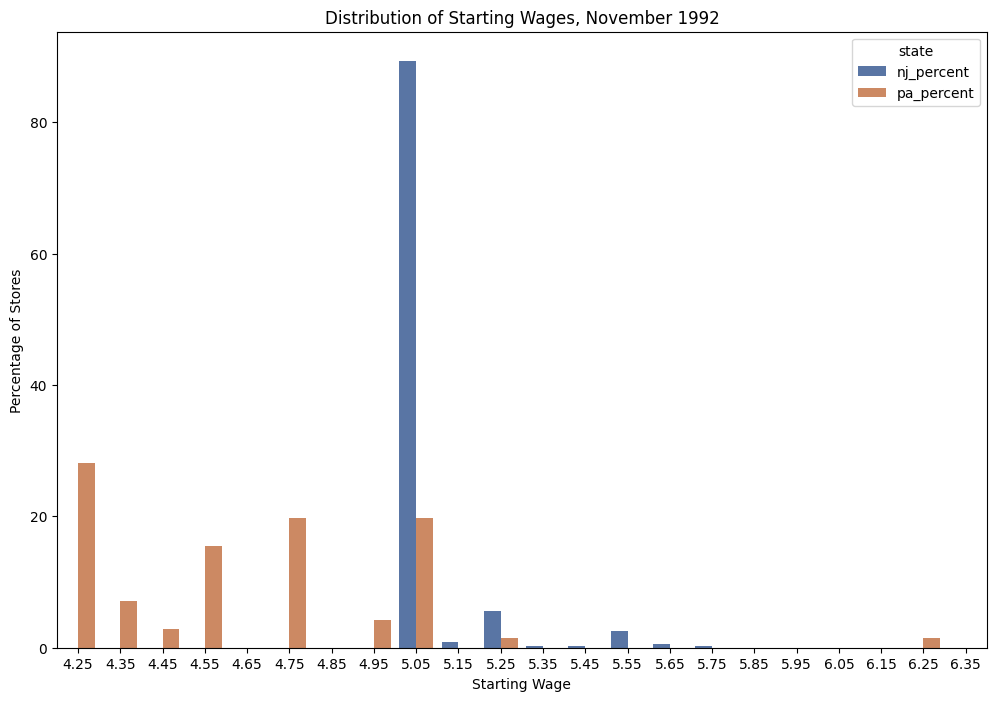

In [166]:
# Reshape the percentages into long format for plotting.
table3_graph = pd.melt(
    table3_countsp,
    id_vars=["category"],
    value_vars=["nj_percent", "pa_percent"],
    var_name="state",
    value_name="percentage"
)

# Plot the distribution of starting wages after the minimum-wage increase.
plt.figure(figsize=(12, 8))
sns.barplot(
    data=table3_graph,
    x='category',
    y='percentage',
    hue='state',
    palette='deep'
)
plt.title('Distribution of Starting Wages, November 1992')
plt.xlabel('Starting Wage')
plt.ylabel('Percentage of Stores');

## Grouping Data for Table 3

We group restaurants by state to calculate mean FTE employment before and after the minimum-wage increase, along with variances and sample sizes. We then calculate standard errors for the means and the change in mean employment for each state. These descriptive statistics help compare employment changes in New Jersey and Pennsylvania.

In [167]:
# Calculate mean FTE employment, variance, and sample size before and after the policy by state.
grouped_data = df.groupby('state').agg(
    mean_before=('fte', 'mean'),
    mean_after=('fte_after', 'mean'),
    var_before=('fte', 'var'),
    var_after=('fte_after', 'var'),
    n_before=('fte', 'count'),
    n_after=('fte_after', 'count')
)
grouped_data

# Calculate standard errors for the employment means.
grouped_data['se_mean_before'] = np.sqrt(grouped_data['var_before'] / grouped_data['n_before'])
grouped_data['se_mean_after'] = np.sqrt(grouped_data['var_after'] / grouped_data['n_after'])

# Label states and calculate the change in mean FTE employment.
grouped_data['state'] = grouped_data.index.map({'0': 'PA', '1': 'NJ'})
grouped_data['change_mean_fte'] = grouped_data['mean_after'] - grouped_data['mean_before']

result_df = grouped_data[
    ['state', 'mean_before', 'mean_after', 'change_mean_fte',
     'se_mean_before', 'se_mean_after']
]
result_df

,state,mean_before,mean_after,change_mean_fte,se_mean_before,se_mean_after
state,,,,,,
0,PA,23.331169,21.165584,-2.165584,1.351149,0.943221
1,NJ,20.439408,21.027429,0.588021,0.508261,0.520309


# Robustness : Balanced Sample

As a robustness check, we restrict the analysis to restaurants with observed FTE employment in both survey waves. In the original calculations, the before and after means may be based on different numbers of restaurants because some observations are missing. Using a balanced sample ensures that the comparison includes only restaurants observed in both periods, allowing us to assess whether the results are sensitive to changes in sample composition.

In [168]:
# Exclude restaurants with missing FTE employment in either survey wave.
filtered_data = df.dropna(subset=['fte', 'fte_after'])

# Calculate mean employment before and after the policy using the balanced sample.
balanced_sample = filtered_data.groupby('state').agg(
    mean_before_balanced=('fte', 'mean'),
    mean_after_balanced=('fte_after', 'mean')
)

# Calculate the change in mean employment and label each state.
balanced_sample['change_mean_fte_balanced'] = (
    balanced_sample['mean_after_balanced'] - balanced_sample['mean_before_balanced']
)
balanced_sample['state'] = balanced_sample.index.map({'0': 'PA', '1': 'NJ'})

result_balanced_df = balanced_sample[['state', 'change_mean_fte_balanced']]

# Merge balanced-sample changes with the original results for comparison.
result_df = result_df.reset_index(drop=True)
result_balanced_df = result_balanced_df.reset_index(drop=True)
full_table = pd.merge(result_df, result_balanced_df, how='left', on='state')

full_table = full_table[
    ['state', 'mean_before', 'mean_after', 'se_mean_before',
     'se_mean_after', 'change_mean_fte', 'change_mean_fte_balanced']
]

# Reshape the results to compare Pennsylvania and New Jersey side by side.
transposed = full_table.T
transposed.columns = ['PA', 'NJ']
result = transposed.drop(index='state').rename_axis('variable').reset_index()

# Calculate the difference between New Jersey and Pennsylvania for each statistic.
result['PA'] = pd.to_numeric(result['PA'], errors='coerce')
result['NJ'] = pd.to_numeric(result['NJ'], errors='coerce')
result['Diff_NJ-PA'] = result['NJ'] - result['PA']

result

,variable,PA,NJ,Diff_NJ-PA
0,mean_before,23.331169,20.439408,-2.891761
1,mean_after,21.165584,21.027429,-0.138155
2,se_mean_before,1.351149,0.508261,-0.842888
3,se_mean_after,0.943221,0.520309,-0.422912
4,change_mean_fte,-2.165584,0.588021,2.753606
5,change_mean_fte_balanced,-2.283333,0.466667,2.750000


### Reshaping the Data and Estimating Difference-in-Differences

To estimate the employment effect using a difference-in-differences (DID) regression, we reshape the data so that each restaurant has a separate observation for each survey period. The period indicator distinguishes observations before and after the minimum-wage increase, while the state indicator identifies New Jersey as the treatment group and Pennsylvania as the control group. We first estimate a basic model and then add restaurant-chain, ownership, and location controls to examine whether the estimated effect changes after accounting for these characteristics.

In [169]:
# Stack before- and after-policy employment observations, using a dummy to identify the period.
before = df[['state', 'co_owned', 'centralj', 'southj', 'chain', 'pa1', 'fte']].copy()
before = before.rename(columns={'fte': 'fte_total'})
before['d'] = 0

after = df[['state', 'co_owned', 'centralj', 'southj', 'chain', 'pa1', 'fte_after']].copy()
after = after.rename(columns={'fte_after': 'fte_total'})
after['d'] = 1

fte_total = pd.concat([before, after], ignore_index=True)

# Estimate the basic difference-in-differences model.
from statsmodels.formula.api import ols
reg = ols('fte_total ~ d + state + d*state', data=fte_total).fit()
print(reg.summary())

# Create restaurant-chain dummy variables for the controlled regression.
for i in range(1, 5):
    fte_total[f'chain{i}'] = (fte_total['chain'] == i).astype(int)

# Re-estimate the model controlling for chain, ownership, and location characteristics.
reg2 = ols(
    'fte_total ~ state + d + state*d + chain2 + chain3 + chain4 + co_owned + centralj + southj + pa1',
    data=fte_total
).fit()
print(reg2.summary())

                            OLS Regression Results                            
Dep. Variable:              fte_total   R-squared:                       0.007
Model:                            OLS   Adj. R-squared:                  0.004
Method:                 Least Squares   F-statistic:                     1.964
Date:                Sat, 24 Oct 2026   Prob (F-statistic):              0.118
Time:                        22:51:56   Log-Likelihood:                -2904.2
No. Observations:                 794   AIC:                             5816.
Df Residuals:                     790   BIC:                             5835.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       23.3312      1.072     21.767   

### Preparing the Estimation Sample and Measuring Policy Exposure

We construct the estimation sample by excluding restaurants with missing values in the employment and wage variables required for the analysis. We then calculate the change in FTE employment between the two survey waves under the baseline and alternative employment definitions. Finally, we construct the initial wage-gap measure, which captures the relative increase required to bring a New Jersey restaurant's starting wage up to the new minimum wage of $5.05. Restaurants in Pennsylvania and New Jersey that already paid above this threshold are assigned a gap of zero. This measure allows us to examine whether employment changes varied with restaurants' exposure to the policy.

In [170]:
# Create the estimation sample and exclude observations missing key employment or wage variables.
est_df = df.copy()
est_df = est_df.dropna(
    subset=['fte', 'fte_after', 'fte2', 'fte_after2', 'wage_st', 'wage_st2']
)

# Calculate changes in employment under the baseline and alternative FTE specifications.
est_df['delta_emp'] = est_df['fte_after'] - est_df['fte']
est_df['state'] = est_df['state'].astype(int)
est_df['delta_emp2'] = est_df['fte_after2'] - est_df['fte2']
est_df['delta_emp3'] = est_df['fte_after3'] - est_df['fte3']
est_df['delta_emp4'] = est_df['fte_after4'] - est_df['fte4']

# Measure exposure to the minimum-wage increase using New Jersey restaurants' initial wages.
est_df['gap'] = 0
est_df.loc[
    (est_df['state'] == 1) & (est_df['wage_st'] <= 5.05),
    'gap'
] = (5.05 - est_df['wage_st']) / est_df['wage_st']

# Create chain dummy variables for the regression controls.
for i in range(1, 5):
    est_df[f'chain{i}'] = (est_df['chain'] == i).astype(int)

/tmp/ipykernel_720/3838485894.py:16: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.01       0.01       0.01       0.01       0.01       0.01
 0.01       0.01       0.01       0.01       0.01       0.01
 0.         0.01       0.01       0.01       0.01       0.01
 0.01       0.01       0.01       0.01       0.01       0.01
 0.01       0.01       0.01       0.01       0.         0.01
 0.01       0.01       0.01       0.01       0.01       0.01
 0.         0.01       0.01       0.01       0.01       0.01
 0.01       0.01       0.12222222 0.06315789 0.18823529 0.06315789
 0.12222222 0.15560641 0.18823529 0.18823529 0.15560641 0.12222222
 0.09782609 0.12222222 0.15560641 0.18823529 0.18823529 0.13483146
 0.16091954 0.12222222 0.06315789 0.12222222 0.12222222 0.02020202
 0.12222222 0.18823529 0.12222222 0.18823529 0.12222222 0.18823529
 0.18823529 0.12222222 0.06315789 0.18823529 0.18823529 0.18823529
 0.12

In [171]:
# Running OLS Linear Regression models with different combinations of independent variables

# Model 1 is the employment change explained by a New Jersey indicator
model1 = ols('delta_emp ~ state', data = est_df).fit()

# Model 2 adds chained and ownership controls
model2 = ols('delta_emp ~ state + co_owned + chain2 + chain3 + chain4', data = est_df).fit()

# Model 3 uses the intial wage gap as the main explanatory variable
model3 = ols('delta_emp ~ gap', data = est_df).fit()

# Model 4 adds chain and ownership controls to Model 3
model4 = ols('delta_emp ~ gap + co_owned + chain2 + chain3 + chain4', data = est_df).fit()

# Model 5 adds chain, ownership controls, and regional/state-related controls to Model 3
model5 = ols('delta_emp ~ gap + co_owned + chain2 + chain3 + chain4 + southj + centralj + northj + pa1', data = est_df).fit()

In [172]:
# Isolating coefficients, standard errors, and standard errors of regression
mod1_coeffs = model1.params
mod1_SE = model1.bse
mod1_RSE = model1.scale**.5
mod2_coeffs = model2.params
mod2_SE = model2.bse
mod2_RSE = model2.scale**.5
mod3_coeffs = model3.params
mod3_SE = model3.bse
mod3_RSE = model3.scale**.5
mod4_coeffs = model4.params
mod4_SE = model4.bse
mod4_RSE = model4.scale**.5
mod5_coeffs = model5.params
mod5_SE = model5.bse
mod5_RSE = model5.scale**.5

### Constructing Table 4

We extract the estimated coefficients, their standard errors, and the residual standard errors from each regression model and organize them into a table for comparison. The table also reports tests of whether the additional control variables are jointly significant when compared with the corresponding restricted model. This summarizes how the estimated relationship between minimum-wage exposure and employment changes across specifications.

In [181]:
Table4 = pd.DataFrame({
    'Independent_variable': [
        "New Jersey dummy",
        "Initial wage gap",
        "Controls for chain and ownership",
        "Controls for region",
        "Standard error of regression",
        "Probability value for controls"
    ],
    'Model1_Coeff': [
        round(mod1_coeffs.iloc[1], 2), "-", "no", "no",
        round(mod1_RSE, 2), "-"
    ],
    'Model1_SE': [
        round(mod1_SE.iloc[1], 2), "-", "-", "-",
        "-", "-"
    ],
    'Model2_Coeff': [
        round(mod2_coeffs.iloc[1], 2), "-", "yes", "no",
        round(mod2_RSE, 2), round(model2.compare_f_test(model1)[1], 2)
    ],
    'Model2_SE': [
        round(mod2_SE.iloc[1], 2), "-", "-", "-",
        "-", "-"
    ],
    'Model3_Coeff': [
        "-", round(mod3_coeffs.iloc[1], 2), "no", "no",
        round(mod3_RSE, 2), "-"
    ],
    'Model3_SE': [
        "-", round(mod3_SE.iloc[1], 2), "-", "-",
        "-", "-"
    ],
    'Model4_Coeff': [
        "-", round(mod4_coeffs.iloc[1], 2), "yes", "no",
        round(mod4_RSE, 2), round(model4.compare_f_test(model3)[1], 2)
    ],
    'Model4_SE': [
        "-", round(mod4_SE.iloc[1], 2), "-", "-",
        "-", "-"
    ],
    'Model5_Coeff': [
        "-", round(mod5_coeffs.iloc[1], 2), "yes", "yes",
        round(mod5_RSE, 2), round(model5.compare_f_test(model3)[1], 2)
    ],
    'Model5_SE': [
        "-", round(mod5_SE.iloc[1], 2), "-", "-",
        "-", "-"
    ]
})

Table4

,Independent_variable,Model1_Coeff,Model1_SE,Model2_Coeff,Model2_SE,Model3_Coeff,Model3_SE,Model4_Coeff,Model4_SE,Model5_Coeff,Model5_SE
0,New Jersey dummy,2.28,1.19,2.28,1.2,-,-,-,-,-,-
1,Initial wage gap,-,-,-,-,17.05,6.09,16.36,6.24,13.88,7.44
2,Controls for chain and ownership,no,-,yes,-,no,-,yes,-,yes,-
3,Controls for region,no,-,no,-,no,-,no,-,yes,-
4,Standard error of regression,8.71,-,8.72,-,8.66,-,8.68,-,8.67,-
5,Probability value for controls,-,-,0.48,-,-,-,0.62,-,0.48,-


### Interpreting the Wage-Gap Estimate

We use the estimated coefficient on the initial wage-gap variable to calculate the predicted employment change associated with the average wage-gap exposure among New Jersey restaurants. We also examine the fully controlled regression model to assess the relationship between minimum-wage exposure and employment changes after accounting for restaurant characteristics and location.

In [174]:
#Finds mean value of GAP among New Jersey stores
mean_gap = est_df.loc[est_df['state'] == 1, 'gap'].mean()
delta_FTE_gap = mean_gap * mod3_coeffs.iloc[1]
print("Mean value of GAP among NJ stores is", mean_gap.round(3))
print("An increase in FTE employment in NJ relative to PA of", delta_FTE_gap.round(3))

print(model5.summary())


Mean value of GAP among NJ stores is 0.105
An increase in FTE employment in NJ relative to PA of 1.783
                            OLS Regression Results                            
Dep. Variable:              delta_emp   R-squared:                       0.043
Model:                            OLS   Adj. R-squared:                  0.018
Method:                 Least Squares   F-statistic:                     1.704
Date:                Sat, 24 Oct 2026   Prob (F-statistic):             0.0868
Time:                        22:51:56   Log-Likelihood:                -1251.1
No. Observations:                 351   AIC:                             2522.
Df Residuals:                     341   BIC:                             2561.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------

### Table 5: Alternative Employment Specifications

To test the robustness of the results, we re-estimate the employment-change regressions using alternative definitions of FTE employment. The first specification excludes managers, while the second and third assign part-time employees weights of 0.4 and 0.6, respectively. For each specification, we estimate models using both the New Jersey indicator and the initial wage-gap measure, allowing us to assess whether the findings depend on how employment is measured.

In [175]:
# Table 5: Alternative employment specifications

# Spec 1: Exclude managers
spec1 = ols('delta_emp2 ~ state + co_owned + chain2 + chain3 + chain4', data=est_df).fit()
spec1_gap = ols('delta_emp2 ~ gap + co_owned + chain2 + chain3 + chain4', data=est_df).fit()


# Spec 2: Part-time workers weighted at 0.4
spec2 = ols('delta_emp3 ~ state + co_owned + chain2 + chain3 + chain4', data=est_df).fit()
spec2_gap = ols('delta_emp3 ~ gap + co_owned + chain2 + chain3 + chain4', data=est_df).fit()


# Spec 3: Part-time workers weighted at 0.6
spec3 = ols('delta_emp4 ~ state + co_owned + chain2 + chain3 + chain4', data=est_df).fit()
spec3_gap = ols('delta_emp4 ~ gap + co_owned + chain2 + chain3 + chain4', data=est_df).fit()

In [176]:
spec1_coeffs = spec1.params
spec1_SE = spec1.bse

spec1_gap_coeffs = spec1_gap.params
spec1_gap_SE = spec1_gap.bse

spec2_coeffs = spec2.params
spec2_SE = spec2.bse

spec2_gap_coeffs = spec2_gap.params
spec2_gap_SE = spec2_gap.bse

spec3_coeffs = spec3.params
spec3_SE = spec3.bse

spec3_gap_coeffs = spec3_gap.params
spec3_gap_SE = spec3_gap.bse

In [177]:
Table5 = pd.DataFrame({
    'Specification': ["Base specification", "Exclude managers in employment count", "Weight part-time as 0.4 x full-time", "Weight part-time as 0.6 x full-time"],
    'NJDummy_Coeff': [round(mod2_coeffs.iloc[1], 2), round(spec1_coeffs.iloc[1], 2), round(spec2_coeffs.iloc[1], 2), round(spec3_coeffs.iloc[1], 2)],
    'NJDummy_SE': [round(mod2_SE.iloc[1], 2), round(spec1_SE.iloc[1], 2), round(spec2_SE.iloc[1], 2), round(spec3_SE.iloc[1], 2)],
    'GapMeasure_Coeff': [round(mod4_coeffs.iloc[1], 2), round(spec1_gap_coeffs.iloc[1], 2), round(spec2_gap_coeffs.iloc[1], 2), round(spec3_gap_coeffs.iloc[1], 2)],
    'GapMeasure_SE': [round(mod4_SE.iloc[1], 2), round(spec1_gap_SE.iloc[1], 2), round(spec2_gap_SE.iloc[1], 2), round(spec3_gap_SE.iloc[1], 2)],
})

print(Table5)

                          Specification  NJDummy_Coeff  NJDummy_SE  \
0                    Base specification           2.28        1.20   
1  Exclude managers in employment count           2.30        1.17   
2   Weight part-time as 0.4 x full-time           2.33        1.21   
3   Weight part-time as 0.6 x full-time           2.23        1.20   

   GapMeasure_Coeff  GapMeasure_SE  
0             16.36           6.24  
1             15.79           6.12  
2             16.58           6.29  
3             16.14           6.27  


In [178]:
Table3 = est_df.groupby('state')[['fte', 'fte_after']].mean()

control_intercept = Table3.loc[0, 'fte']
treat_intercept_delta = Table3.loc[1, 'fte'] - Table3.loc[0, 'fte']
trend = Table3.loc[0, 'fte_after'] - Table3.loc[0, 'fte']
Δ = (Table3.loc[1, 'fte_after'] - Table3.loc[1, 'fte']) - trend
intervention_time = 0.5

print("Control intercept:", control_intercept)
print("Initial treatment-control difference:", treat_intercept_delta)
print("Control group trend:", trend)
print("DID estimate:", Δ)

Control intercept: 23.704545454545453
Initial treatment-control difference: -3.026299840510365
Control group trend: -1.878787878787879
DID estimate: 2.2768580542264765


In [179]:
# Function that calculates the expected value of the outcome
def outcome(t, control_intercept, treat_intercept_delta, trend, Δ, group, treated):
    return control_intercept + (treat_intercept_delta * group) + (t * trend) + (Δ * treated * group)

# Function used to calculate the dummy treatment variable
def is_treated(t, intervention_time, group):
    return (t > intervention_time) * group

# Using sample mean values from Table 3 to calculate the DID
# Using sample mean values from our dataset to calculate the DID
control_intercept = 23.70
treat_intercept_delta = -3.03
trend = -1.88
Δ = 2.28
intervention_time = 0.5

### Visualizing the Difference-in-Differences Estimate

We use the mean FTE employment values for New Jersey and Pennsylvania before and after the minimum-wage increase to construct an illustrative difference-in-differences graph. The graph shows the observed employment paths for the treatment and control groups, alongside the counterfactual path representing employment in New Jersey had its employment trend followed that of Pennsylvania. The difference between the observed New Jersey outcome and this counterfactual outcome represents the estimated treatment effect. This interpretation relies on the parallel-trends assumption, and the graph illustrates the estimated effect rather than displaying individual restaurant observations.

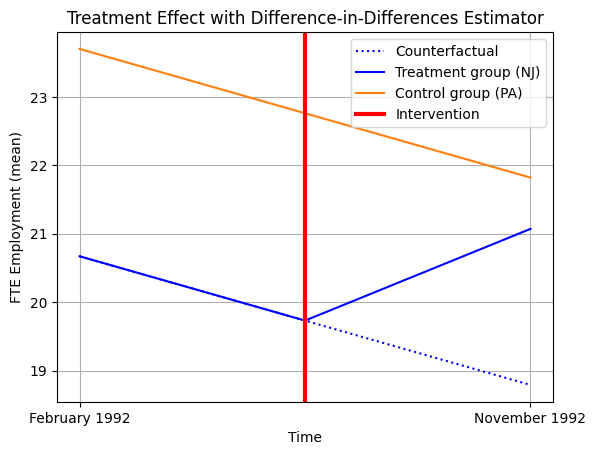

In [180]:
# Plotting DID
fig, ax = plt.subplots()
ti = np.linspace(0, 1, 3)

ax.plot(
    ti,
    outcome(ti, control_intercept, treat_intercept_delta, trend, Δ=0, group=1,
            treated=is_treated(ti, intervention_time, group=1)),
    color="blue", label="Counterfactual", ls=":"
)
ax.plot(
    ti,
    outcome(ti, control_intercept, treat_intercept_delta, trend, Δ, group=1,
            treated=is_treated(ti, intervention_time, group=1)),
    color="blue", label="Treatment group (NJ)"
)
ax.plot(
    ti,
    outcome(ti, control_intercept, treat_intercept_delta, trend, Δ, group=0,
            treated=is_treated(ti, intervention_time, group=0)),
    color="C1", label="Control group (PA)"
)

ax.axvline(x=intervention_time, ls="-", color="r", label="Intervention", lw=3)
t = np.array([0, 1])

ax.set(
    xlabel="Time",
    ylabel="FTE Employment (mean)",
    xticks=t,
    xticklabels=["February 1992", "November 1992"],
    title="Treatment Effect with Difference-in-Differences Estimator"
)
ax.legend()
plt.grid()
plt.show()